In [6]:
from dotenv import load_dotenv
load_dotenv()

True

In [10]:
!pip install tavily-python

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import os
import operator

import asyncio
from tavily import TavilyClient, AsyncTavilyClient

from typing import Literal,Annotated
from pydantic import BaseModel

from langchain_groq import ChatGroq
from langchain_core.messages  import HumanMessage, SystemMessage, AIMessage, ToolMessage
from langchain_core.tools  import tool
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import  RecursiveCharacterTextSplitter
from langchain_google_genai import ChatGoogleGenerativeAI,GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode

In [8]:
#load PDF 

loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()
print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [9]:
raw_docs[0].page_content

'Will EVs Dampen the Oil Price\n Shock?\nElectric Vehicles, Oil Demand Destruction, and the Future of Energy Price\n Volatility\n Version 1.0   |   April 2026\n Technical Reference Document'

In [10]:
# split documents into chunks

chunks = RecursiveCharacterTextSplitter(chunk_size =500, chunk_overlap =100).split_documents(raw_docs)
print(f"Number of chunks after splitting  = {len(chunks)} chunks")

Number of chunks after splitting  = 98 chunks


In [11]:
#initializing the embedding model
embeddings =  GoogleGenerativeAIEmbeddings( model = "gemini-embedding-001",# or 'models/gemini-embedding-exp-03-07'
    task_type="retrieval_document"# Options: retrieval_query, retrieval_document, semantic_similarity, etc.
)

In [12]:
# in-memory only; re-running this cell re-embeds from scratch
vector_store = Chroma(collection_name = "rag_conditional",embedding_function = embeddings)
vector_store.add_documents(documents = chunks)
retriever = vector_store.as_retriever(search_kwargs ={"k":4})
print("Vector store is ready")

Vector store is ready


In [13]:
#initializing LLM
llm = ChatGroq(model="openai/gpt-oss-120b")
agent_llm = ChatGroq(model="openai/gpt-oss-120b")
#llm = ChatGoogleGenerativeAI(model = "gemini-2.5-flash")# route_question and generate
#agent_llm = ChatGoogleGenerativeAI(model = "gemini-2.5-flash") # agent node; tools bound later

In [14]:
#Graph State
class AgenticRAGState(MessagesState):
    query : str
    retrieved_docs : Annotated[list[Document] ,operator.add]
    context : Annotated[str,operator.add]
    generation : str
    needs_retrieval : bool

In [15]:
# structured output schema for the routing decision
class RouteDecision(BaseModel):
    needs_retrieval : bool

In [16]:
#tool
@tool(response_format = "content_and_artifact")
def vector_store_search(query:str , k:int= 3):
    """
    Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages.
    """
    retriever = vector_store.as_retriever(search_kwargs = {"k":k})
    docs = retriever.invoke(query)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return  context, docs

In [17]:
@tool(response_format = "content_and_artifact")
def web_search(query : str, max_results:int =3):
    """
    Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned.
    """
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    response = client.search(query,max_results = max_results)
    docs = [
        Document(
            page_content = r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [18]:
tools = [vector_store_search,web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [19]:
# route_question node — classifies whether the query needs document retrieval
def route_question(state:AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        ("system","Classify whether the following question requires retrieving information from a specialized document, or can be answered from your own general knowledge."),
        ("human","{query}"),
    ])
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query" : state["query"]})
    return {"needs_retrieval" : decision.needs_retrieval}

In [20]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)
# agent node — decides which tool(s) to call based on the query
def agent(state:AgenticRAGState) -> dict:
    messages = state["messages"]
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]
    response =agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [21]:
# collect_tool_output node — drains ToolMessages into state fields
def collect_tool_output(state: AgenticRAGState) -> dict:
    tool_messages = state.get("current_tool_messages", [])
    all_docs, context_parts = [], []
    for msg in tool_messages:
        context_parts.append(msg.content)
        if hasattr(msg, 'artifact') and msg.artifact:
            all_docs.extend(msg.artifact)
    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
        "current_tool_messages": [] # Clear it out for the next turn
    }

In [22]:
# collect_tool_output node — drains ToolMessages into state fields
def collect_tool_output(state: AgenticRAGState) -> dict:
    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []
    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [23]:
# generates a response using the retrieved context
def generate(state: AgenticRAGState) -> dict:
    query = state["query"]
    messages = state["messages"]
    context = state.get("context") or ""
    # Clean message history for Gemini: Remove dangling ToolMessages 
    # since their content is already safely packed into the 'context' variable
    cleaned_messages = [msg for msg in messages if not isinstance(msg, ToolMessage)]
    if context:
        prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
        ("human", "{query}"),
        ])

        response = (prompt_template | llm).invoke({"context": context, "query": query})
    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})
    return {"generation": response.content}

In [24]:
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

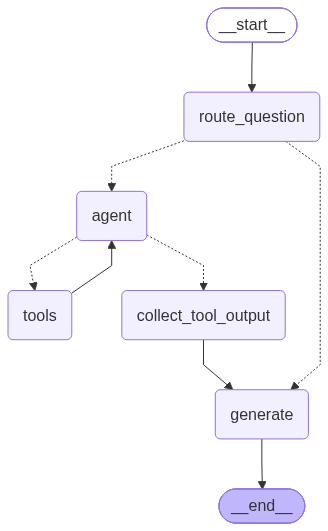

In [25]:
#build graph
builder = StateGraph(AgenticRAGState)

builder.add_node("route_question",route_question)
builder.add_node("agent",agent)
builder.add_node("tools",tool_node)
builder.add_node("collect_tool_output",collect_tool_output)
builder.add_node("generate",generate)

builder.add_edge(START,"route_question")
builder.add_conditional_edges("route_question",route_after_classification)
builder.add_conditional_edges("agent",route_after_agent)
builder.add_edge("tools","agent")
builder.add_edge("collect_tool_output","generate")
builder.add_edge("generate", END)

graph = builder.compile()
graph

In [26]:
# Case 1: vector store only — domain-specific question about the PDF
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [27]:
print("=== CASE 1: Vector Store Only ===")
print(f"needs_retrieval : {result_vs['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_vs.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_vs.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_vs['generation']}")

=== CASE 1: Vector Store Only ===
needs_retrieval : True
retrieved_docs  : 14 docs
context preview : 

## Vector Store Results

million EVs would therefore displace approximately 4.6 million barrels of oil per day by 2030...

Generation:
The report makes clear that electric‑vehicle (EV) growth will cut oil use, but the timing and magnitude differ across the near‑ and long‑term:

* **Near‑term (through 2030)** – Even a rapid build‑out of EVs only trims oil demand modestly.  The analysis estimates that the first million EVs on the road would displace about **4.6 million barrels of oil per day by 2030**, which is a noticeable reduction but still a small fraction of the world’s roughly 100 million‑barrel‑per‑day demand.  In other words, EV penetration will “shave meaningful but modest volumes from global oil demand growth,” delaying a peak rather than preventing it and offering only partial insulation from supply‑driven price shocks.

* **Mid‑term (2035‑2040)** – As the fleet expands, the 

In [28]:
print(result_vs["context"])



## Vector Store Results

million EVs would therefore displace approximately 4.6 million barrels of oil per day by 2030
— a meaningful but not transformative reduction against a global demand base of 100 to 105
million barrels per day. In the 2035–2040 period, displacement could reach 10 to 15 million
barrels per day, sufficient to bring absolute oil demand into structural decline. The IEA's
Announced Pledges Scenario places oil demand peaking before 2030 under current policy

and cushion economies against future oil price shocks? This report examines that question
from multiple angles, drawing on demand trajectory modeling, macroeconomic transmission
mechanisms, producer response dynamics, and the structural limits of EV-led demand
destruction.
 The central finding of this analysis is nuanced. In the near term — through 2030 — EV
penetration will shave meaningful but modest volumes from global oil demand growth, likely

penetration will shave meaningful but modest volumes from global

In [29]:
# Case 2: web search only — current information not in the PDF
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})

In [30]:
print("=== CASE 2: Web Search Only ===")
print(f"needs_retrieval : {result_web['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_web.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_web.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_web['generation']}")

=== CASE 2: Web Search Only ===
needs_retrieval : True
retrieved_docs  : 5 docs
context preview : 

## Web Search Results

## FAQs About New Delhi Weather Conditions

1. What is the current temperature in New Delhi tod...

Generation:
The current temperature in New Delhi is **32 °C** (feels like 36 °C).


In [31]:
# Case 3: both tools — requires document context AND current web data
query_both = "Compare what the EV report projects for 2030 oil demand and also tell me about the weather in mumbai"

result_both = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": ""})

APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `openai/gpt-oss-120b` in organization `org_01kyp4n028e7jrvtf81kn8an87` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Requested 8503, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

In [ ]:
print("=== CASE 3: Both Tools ===")
print(f"needs_retrieval : {result_both['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_both.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_both.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_both['generation']}")

In [ ]:
print(result_both["context"])

In [32]:
# Case 4: no retrieval — answerable from general knowledge
query_none = "Explain the difference between kinetic energy and potential energy."

result_none = graph.invoke({"query": query_none, "messages": [], "retrieved_docs": [], "context": ""})

In [33]:
print("=== CASE 4: No Retrieval ===")
print(f"needs_retrieval : {result_none['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_none.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_none.get('context', '') or '(none)'}")
print(f"\nGeneration:\n{result_none['generation']}")

=== CASE 4: No Retrieval ===
needs_retrieval : False
retrieved_docs  : 0 docs
context preview : (none)

Generation:
**Kinetic energy** and **potential energy** are the two main forms of mechanical energy.  
Both can be expressed in joules (J) in the SI system, but they describe very different aspects of a system’s ability to do work.

---

## 1. Kinetic Energy (KE)

| Aspect | Description |
|--------|-------------|
| **What it is** | Energy associated with the **motion** of an object. |
| **When it exists** | Whenever an object has a non‑zero velocity relative to a chosen reference frame. |
| **Formula (classical mechanics)** | \[
\text{KE} = \frac{1}{2} m v^{2}
\] where **m** is the mass (kg) and **v** is the speed (m·s⁻¹). |
| **Key features** | • Increases with the square of speed – doubling the speed quadruples the kinetic energy.<br>• Depends only on the object's mass and speed, not on its position.<br>• Can be transferred to other objects via collisions, friction, or other intera